# Previsão de score de crédito

**Problema:** um banco quer classificar o score de crédito dos clientes em `Good`, `Standard` ou `Poor` a partir do perfil financeiro (renda, dívidas, atrasos, cartões, empréstimos...).

**O que este notebook faz:**
1. Explora a base (100 mil registros, 12.500 clientes, 8 meses cada).
2. Monta um *pipeline* de pré-processamento + modelo, sem vazamento de dados.
3. Compara a avaliação com divisão aleatória e com divisão **por cliente**, mostrando por que a primeira engana.
4. Escolhe o modelo, analisa os erros e prevê o score de clientes novos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMENTE = 42  # deixa os resultados reproduzíveis

## 1. Explorando a base

In [2]:
clientes = pd.read_csv("clientes.csv")
print(clientes.shape)
clientes.head()

(100000, 25)


,id_cliente,mes,idade,profissao,salario_anual,num_contas,num_cartoes,juros_emprestimo,num_emprestimos,dias_atraso,...,idade_historico_credito,investimento_mensal,comportamento_pagamento,saldo_final_mes,score_credito,emprestimo_carro,emprestimo_casa,emprestimo_pessoal,emprestimo_credito,emprestimo_estudantil
0,3392,1,23.0,cientista,19114.12,3.0,4.0,3.0,4.0,3.0,...,265.0,21.46538,alto_gasto_pagamento_baixos,312.494089,Good,1,1,1,1,0
1,3392,2,23.0,cientista,19114.12,3.0,4.0,3.0,4.0,3.0,...,266.0,21.46538,baixo_gasto_pagamento_alto,284.629162,Good,1,1,1,1,0
2,3392,3,23.0,cientista,19114.12,3.0,4.0,3.0,4.0,3.0,...,267.0,21.46538,baixo_gasto_pagamento_medio,331.209863,Good,1,1,1,1,0
3,3392,4,23.0,cientista,19114.12,3.0,4.0,3.0,4.0,5.0,...,268.0,21.46538,baixo_gasto_pagamento_baixo,223.451310,Good,1,1,1,1,0
4,3392,5,23.0,cientista,19114.12,3.0,4.0,3.0,4.0,6.0,...,269.0,21.46538,alto_gasto_pagamento_medio,341.489231,Good,1,1,1,1,0


In [3]:
# Distribuição da classe que quero prever: é desbalanceada (Standard domina)
clientes["score_credito"].value_counts(normalize=True).round(3)

score_credito
Standard    0.532
Poor        0.290
Good        0.178
Name: proportion, dtype: float64

In [4]:
# Cada cliente aparece em 8 meses diferentes. Isso vai importar na hora de separar treino e teste.
por_cliente = clientes.groupby("id_cliente")
print("clientes únicos:", clientes["id_cliente"].nunique())
print("linhas por cliente:", por_cliente.size().unique())
print("clientes cujo score muda entre os meses:", f'{(por_cliente["score_credito"].nunique() > 1).mean():.0%}')

clientes únicos: 12500
linhas por cliente: [8]
clientes cujo score muda entre os meses: 58%


## 2. Pré-processamento dentro de um pipeline

Na versão anterior deste projeto eu usava um único `LabelEncoder` com `fit_transform` em cada coluna de texto, e depois chamava `fit_transform` **de novo** nos clientes novos. Isso tem dois problemas:

- o encoder era reajustado a cada coluna e a cada base, então o código numérico de uma profissão nos clientes novos podia não ser o mesmo do treino;
- o `LabelEncoder` cria uma ordem falsa entre categorias (`advogado=0 < arquiteto=1 < ...`).

Agora as colunas de texto passam por um `OneHotEncoder` ajustado **só no treino** e guardado dentro do `Pipeline`. Na previsão o pipeline só aplica o `transform`, com as mesmas regras.

In [5]:
ALVO = "score_credito"
categoricas = ["profissao", "mix_credito", "comportamento_pagamento"]
# id_cliente e mes não descrevem o perfil do cliente, então ficam de fora
numericas = [col for col in clientes.columns if col not in categoricas + [ALVO, "id_cliente", "mes"]]

x = clientes[categoricas + numericas]
y = clientes[ALVO]
grupos = clientes["id_cliente"]

def montar_pipeline(modelo):
    preprocessamento = ColumnTransformer([
        ("texto", OneHotEncoder(handle_unknown="ignore"), categoricas),
        ("numeros", StandardScaler(), numericas),  # o KNN depende de escala; pra árvore não faz diferença
    ])
    return Pipeline([("prep", preprocessamento), ("modelo", modelo)])

## 3. Por que a divisão aleatória engana

Se eu sorteio linhas, os 8 meses de um mesmo cliente se espalham entre treino e teste. O modelo "reconhece" o cliente em vez de aprender o padrão, e a acurácia fica otimista.

O cenário real é prever o score de **clientes que o modelo nunca viu**. Pra simular isso, separo por `id_cliente` com `GroupShuffleSplit`.

In [6]:
def avaliar(x_treino, x_teste, y_treino, y_teste, modelo):
    pipe = montar_pipeline(modelo).fit(x_treino, y_treino)
    return pipe, accuracy_score(y_teste, pipe.predict(x_teste))

floresta = lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMENTE)

# (a) divisão aleatória por linha, como no projeto original
xa_tr, xa_te, ya_tr, ya_te = train_test_split(x, y, test_size=0.3, random_state=SEMENTE, stratify=y)
_, acc_aleatoria = avaliar(xa_tr, xa_te, ya_tr, ya_te, floresta())

# (b) divisão por cliente: nenhum cliente aparece nos dois lados
divisor = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEMENTE)
idx_tr, idx_te = next(divisor.split(x, y, grupos))
x_tr, x_te, y_tr, y_te = x.iloc[idx_tr], x.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
assert set(grupos.iloc[idx_tr]).isdisjoint(grupos.iloc[idx_te])
_, acc_por_cliente = avaliar(x_tr, x_te, y_tr, y_te, floresta())

pd.DataFrame({"acurácia": [acc_aleatoria, acc_por_cliente]},
             index=["divisão aleatória (otimista)", "divisão por cliente (realista)"]).round(3)

,acurácia
divisão aleatória (otimista),0.811
divisão por cliente (realista),0.681


A diferença entre as duas linhas é o quanto a divisão aleatória superestima o modelo. Daqui pra frente toda a avaliação usa a divisão **por cliente**.

## 4. Comparando modelos

In [7]:
resultados = {}
pipelines = {}
for nome, modelo in {"Random Forest": floresta(), "KNN": KNeighborsClassifier(n_neighbors=15)}.items():
    pipelines[nome], resultados[nome] = avaliar(x_tr, x_te, y_tr, y_te, modelo)

resultados["Baseline (sempre 'Standard')"] = (y_te == y_tr.mode()[0]).mean()
pd.Series(resultados, name="acurácia").sort_values(ascending=False).round(3)

Random Forest                   0.681
KNN                             0.641
Baseline (sempre 'Standard')    0.533
Name: acurácia, dtype: float64

## 5. Analisando os erros do melhor modelo

              precision    recall  f1-score   support

        Good      0.555     0.656     0.601      5352
        Poor      0.674     0.651     0.662      8645
    Standard      0.736     0.705     0.720     16003

    accuracy                          0.681     30000
   macro avg      0.655     0.671     0.661     30000
weighted avg      0.686     0.681     0.682     30000



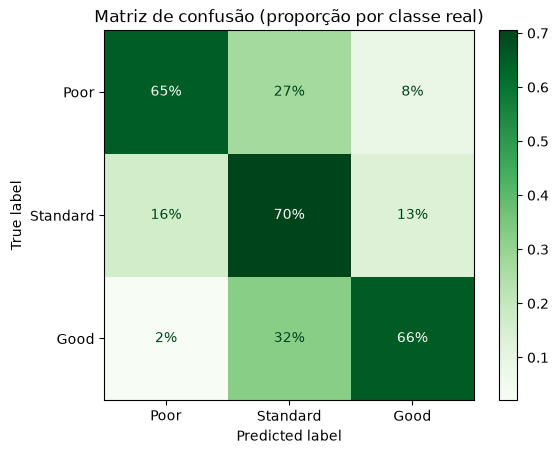

In [8]:
melhor = pipelines["Random Forest"]
previsto = melhor.predict(x_te)
print(classification_report(y_te, previsto, digits=3))
ConfusionMatrixDisplay.from_predictions(y_te, previsto, labels=["Poor", "Standard", "Good"], cmap="Greens", normalize="true", values_format=".0%")
plt.title("Matriz de confusão (proporção por classe real)")
plt.show()

Para um banco, o erro mais caro é classificar como `Good` um cliente que na verdade é `Poor`. A matriz de confusão mostra quanto isso acontece, além da acurácia geral.

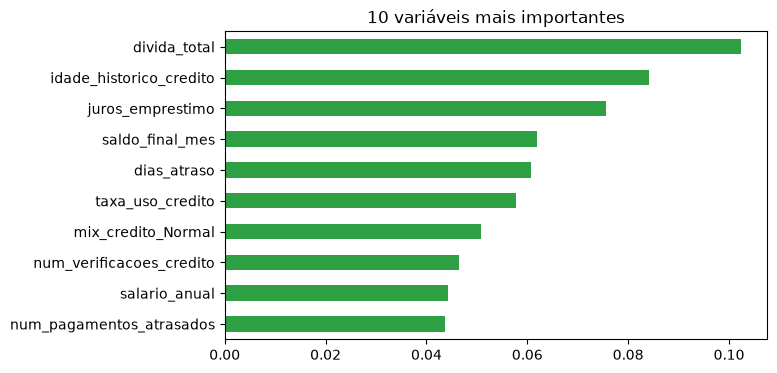

In [9]:
# Quais variáveis mais pesam na decisão da floresta
nomes = melhor.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(melhor.named_steps["modelo"].feature_importances_, index=nomes)
importancias.index = importancias.index.str.replace("numeros__", "").str.replace("texto__", "")
importancias.sort_values().tail(10).plot.barh(color="#2ea043", figsize=(7, 4), title="10 variáveis mais importantes")
plt.show()

## 6. Prevendo clientes novos

O pipeline treinado já carrega o encoder ajustado no treino, então basta passar os dados crus.

In [10]:
novos_clientes = pd.read_csv("novos_clientes.csv")
novos_clientes.assign(score_previsto=melhor.predict(novos_clientes[categoricas + numericas]))[
    ["profissao", "salario_anual", "dias_atraso", "divida_total", "score_previsto"]
]

,profissao,salario_anual,dias_atraso,divida_total,score_previsto
0,empresario,19300.340,52.0,2430.21,Poor
1,advogado,12600.445,25.0,569.80,Poor
2,empresario,20787.690,24.0,614.60,Standard


## Conclusões

- A divisão aleatória superestima o desempenho porque o mesmo cliente aparece no treino e no teste. A avaliação honesta separa por cliente.
- A Random Forest supera o KNN e a baseline, e a matriz de confusão mostra onde ela erra.
- Pré-processamento e modelo ficam num único `Pipeline`, o que evita o erro de reajustar o encoder nos dados novos.

**Próximos passos:** validação cruzada por grupo (`GroupKFold`), ajuste de hiperparâmetros e pesos de classe para penalizar mais o erro `Poor → Good`.